# Quantum-Assisted Resource Allocation for Multi-Agent AI Systems

### Reproducible computational notebook

This notebook accompanies the report **“Quantum-Assisted Resource Allocation for Multi-Agent AI Systems”** by Kien Nguyen (University of Waterloo, November 3, 2026). It implements the report's VQGAPe formulation for one four-task, four-agent example.

The report contains the motivation, derivations, and comparison of VQE, VQGAP, and VQGAPe. This notebook focuses on the executable implementation, numerical checks, and figures. Section references below refer to the accompanying report.

## Problem statement

Suppose a technology company has four specialized LLM agents and four cross-disciplinary tasks. Every task must be assigned to exactly one agent. Assignment $(n,m)$ consumes $a_{nm}$ tokens and has expected success rate $c_{nm}$, while agent $m$ has capacity $b_m$. The goal is to balance completion quality and normalized token consumption without exceeding any capacity.

This is the report's Generalized Assignment Problem instance. See **Sections 1.2–1.4** of the report for the complete mathematical formulation, objective construction, and QUBO penalty derivation.

## 1. Installation and imports

The notebook uses Qiskit to define the parameterized quantum circuit and obtain its statevector. NumPy stores the routing data and evaluates the objective. SciPy's COBYLA optimizer updates the circuit angles without needing derivatives. Matplotlib produces the convergence and schedule-audit visualizations.

Run the installation cell once in a fresh runtime.

In [ ]:
!pip install qiskit

import numpy as np
from scipy.optimize import minimize
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 48.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 52.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [qiskit]


## 2. Example instance

The arrays below instantiate the report's notation: $a_{nm}$ is raw token consumption, $c_{nm}$ is expected success, $b_m$ is agent capacity, and $x_{nm}$ is the binary assignment variable. The combined weight follows Section 1.4:

$$w_{nm}=\lambda\bar{a}_{nm}-(1-\lambda)c_{nm}, \qquad \bar{a}_{nm}=\frac{a_{nm}}{a_{\max}}.$$

For numerical conditioning, the implementation also divides the complete capacity equation by $a_{\max}$, defining $\bar{b}_m=b_m/a_{\max}$. This rescaling does not change which assignments are feasible.

In [ ]:
# 1. Cross-disciplinary tasks and specialized LLM agents
tasks = [
    'T1: RAG Vector Search Pipeline',
    'T2: Real-Time Fraud Telemetry',
    'T3: Automated Code-Review Bot',
    'T4: Distributed API Cache Layer'
]

agents = [
    'Agent 1: Systems/DB (9k)',
    'Agent 2: AI/ML (9.5k)',
    'Agent 3: Security/Infra (9k)',
    'Agent 4: Full-Stack (8.5k)'
]

# Derive register dimensions from the problem size rather than hard-coding
# them. Each task needs ceil(log2(M)) bits to identify one of M agents.
N, M = len(tasks), len(agents)
L = int(np.ceil(np.log2(M)))
Q_vqgap_e = N * L  # Four task registers * two qubits = eight qubits.

# Maximum token capacities b_m, in raw tokens.
b_raw = np.array([9000, 9500, 9000, 8500])

# Token consumption a_nm: rows are tasks and columns are agents.
a_raw = np.array([
    [5200, 5000, 6800, 5800],
    [5400, 5200, 4800, 6500],
    [6200, 5500, 5100, 4600],
    [4200, 6400, 5300, 4900],
])

# Expected success rates c_nm in [0, 1].
c_nm = np.array([
    [0.91, 0.96, 0.74, 0.85],
    [0.84, 0.89, 0.94, 0.76],
    [0.78, 0.95, 0.88, 0.91],
    [0.95, 0.75, 0.83, 0.89],
])

# Use the largest assignment demand as a common scale. Capacities must use
# the same denominator so capacity comparisons remain unchanged.
scale = np.max(a_raw)
a_bar_nm = a_raw / scale
b_bar_m = b_raw / scale

# lambda balances token efficiency against expected success.
lam = 0.35
w_nm = lam * a_bar_nm - (1.0 - lam) * c_nm

# Choose a conservative penalty larger than the total magnitude of every
# local assignment weight. This makes violations expensive in this instance.
C_penalty = 1.0 + np.sum(np.abs(w_nm))

# Reference resource counts. A conventional binary-slack construction needs
# one-hot assignment variables plus binary capacity slack registers.
Q_vqe = N * M + sum(int(np.ceil(np.log2(b + 1))) for b in b_raw)
print('=== QISKIT QUANTUM RESOURCE COMPARISON ===')
print(f'• Standard VQE/QUBO (binary slack):          {Q_vqe} Qubits')
print(f'• VQGAP (one-hot assignment register):       {N * M} Qubits')
print(f'• VQGAPe (logarithmic assignment register):  {Q_vqgap_e} Qubits [{100 * (1 - Q_vqgap_e / Q_vqe):.1f}% reduction vs. VQE]')


=== QISKIT QUANTUM RESOURCE COMPARISON ===
• Standard VQE/QUBO (binary slack):          72 Qubits
• VQGAP (one-hot assignment register):       16 Qubits
• VQGAPe (logarithmic assignment register):  8 Qubits [88.9% reduction vs. VQE]


## 3. Encoded cost table and exact reference

Following **Section 1.7** of the report, each task uses $L=\lceil\log_2M\rceil=2$ qubits and the complete assignment register uses $Q=NL=8$ qubits. The decoder below implements

$$m_n=1+\sum_{\ell=1}^{L}2^{\ell-1}e_{n\ell}.$$

The residual capacities and extended cost $F_{\mathrm{val}}$ follow **Sections 1.6–1.7**. Because this example has only $2^8=256$ encoded states, the notebook enumerates all states to obtain an exact feasible reference for evaluating the variational result.

In [ ]:
def decode_bitstring_to_x(bitstring_int):
    """Convert one encoded basis-state integer into an N-by-M one-hot matrix."""
    # Start with no assignments. Each task row will receive one active entry.
    x_mat = np.zeros((N, M))

    for n in range(N):
        # Task n owns qubits n*L through n*L + L - 1. Python index l=0
        # corresponds to the report's mathematical index ell=1. Qubit q_0
        # is the least-significant bit in Qiskit's statevector indexing.
        agent_idx = 0
        for l in range(L):
            bit_position = n * L + l
            bit = (bitstring_int >> bit_position) & 1
            agent_idx += (1 << l) * bit

        # This guard matters when M is not a power of two and some encoded
        # indices do not correspond to real agents. Here M=4, so all pass.
        if agent_idx < M:
            x_mat[n, agent_idx] = 1.0

    return x_mat


def evaluate_vqgap_cost(x_matrix):
    """Evaluate the weighted objective and both quadratic penalties."""
    # Base routing cost: low token demand and high success reduce this term.
    assignment_cost = np.sum(w_nm * x_matrix)

    # Every task row must contain exactly one selected agent.
    assignments_per_task = np.sum(x_matrix, axis=1)
    assignment_penalty = C_penalty * np.sum((1.0 - assignments_per_task) ** 2)

    # Evaluate capacity in units of a_max. This is a unit conversion of the
    # report's capacity equation and preserves the feasible assignment set.
    used_tokens = np.sum(a_bar_nm * x_matrix, axis=0)
    residual_capacity = np.maximum(0.0, b_bar_m - used_tokens)

    # This residual is zero for a feasible agent. It equals the overflow, up
    # to sign, when used_tokens exceeds the available capacity.
    capacity_residual = b_bar_m - used_tokens - residual_capacity
    capacity_penalty = C_penalty * np.sum(capacity_residual ** 2)

    return assignment_cost + assignment_penalty + capacity_penalty


# Enumerate every computational-basis state. With Q=8, only 256 states
# exist, so an exact classical reference is inexpensive for this example.
num_encoded_states = 1 << Q_vqgap_e
all_x_matrices = [decode_bitstring_to_x(state) for state in range(num_encoded_states)]
all_costs = np.array([evaluate_vqgap_cost(x) for x in all_x_matrices])

# Mark a state feasible only when every agent remains within capacity. The
# tolerance prevents floating-point rounding near a capacity boundary from
# incorrectly classifying an otherwise feasible schedule.
feasible_mask = np.array([
    np.all(np.sum(a_raw * x, axis=0) <= b_raw + 1e-12)
    for x in all_x_matrices
])

# Mask infeasible costs with positive infinity before taking the minimum.
feasible_costs = np.where(feasible_mask, all_costs, np.inf)
optimal_state_idx = int(np.argmin(feasible_costs))
optimal_cost = all_costs[optimal_state_idx]

# Build a simple baseline by choosing the highest-success agent separately
# for each task. This ignores competition for each agent's shared capacity.
greedy_x = np.zeros((N, M))
for n in range(N):
    best_agent_for_task = int(np.argmax(c_nm[n]))
    greedy_x[n, best_agent_for_task] = 1.0
greedy_tokens = np.sum(a_raw * greedy_x, axis=0)

print(f'Naive Greedy Token Usage per Agent: {greedy_tokens.astype(int)} vs Limits {b_raw}')
print(f'--> Greedy Overflows Agent 2 (AI/ML) by {int(greedy_tokens[1] - b_raw[1])} tokens! (Penalized Cost: {evaluate_vqgap_cost(greedy_x):.2f})\n')
print(f'Exact Feasible Global Optimum Cost F*: {optimal_cost:.4f} (Encoded State Integer: {optimal_state_idx})')


Naive Greedy Token Usage per Agent: [ 4200 10500  4800     0] vs Limits [9000 9500 9000 8500]
--> Greedy Overflows Agent 2 (AI/ML) by 1000 tokens! (Penalized Cost: -1.35)

Exact Feasible Global Optimum Cost F*: -1.4866 (Encoded State Integer: 57)


In [ ]:
def decode_bitstring_to_x(bitstring_int):
    """Convert one encoded basis-state integer into an N-by-M one-hot matrix."""
    # Start with no assignments. Each task row will receive one active entry.
    x_mat = np.zeros((N, M))

    for n in range(N):
        # Task n owns qubits n*L through n*L + L - 1. Python index l=0
        # corresponds to the report's mathematical index ell=1. Qubit q_0
        # is the least-significant bit in Qiskit's statevector indexing.
        agent_idx = 0
        for l in range(L):
            bit_position = n * L + l
            bit = (bitstring_int >> bit_position) & 1
            agent_idx += (1 << l) * bit

        # This guard matters when M is not a power of two and some encoded
        # indices do not correspond to real agents. Here M=4, so all pass.
        if agent_idx < M:
            x_mat[n, agent_idx] = 1.0

    return x_mat


def evaluate_vqgap_cost(x_matrix):
    """Evaluate the weighted objective and both quadratic penalties."""
    # Base routing cost: low token demand and high success reduce this term.
    assignment_cost = np.sum(w_nm * x_matrix)

    # Every task row must contain exactly one selected agent.
    assignments_per_task = np.sum(x_matrix, axis=1)
    assignment_penalty = C_penalty * np.sum((1.0 - assignments_per_task) ** 2)

    # Evaluate capacity in units of a_max. This is a unit conversion of the
    # report's capacity equation and preserves the feasible assignment set.
    used_tokens = np.sum(a_bar_nm * x_matrix, axis=0)
    residual_capacity = np.maximum(0.0, b_bar_m - used_tokens)

    # This residual is zero for a feasible agent. It equals the overflow, up
    # to sign, when used_tokens exceeds the available capacity.
    capacity_residual = b_bar_m - used_tokens - residual_capacity
    capacity_penalty = C_penalty * np.sum(capacity_residual ** 2)

    return assignment_cost + assignment_penalty + capacity_penalty


# Enumerate every computational-basis state. With Q=8, only 256 states
# exist, so an exact classical reference is inexpensive for this example.
num_encoded_states = 1 << Q_vqgap_e
all_x_matrices = [decode_bitstring_to_x(state) for state in range(num_encoded_states)]
all_costs = np.array([evaluate_vqgap_cost(x) for x in all_x_matrices])

# Mark a state feasible only when every agent remains within capacity. The
# tolerance prevents floating-point rounding near a capacity boundary from
# incorrectly classifying an otherwise feasible schedule.
feasible_mask = np.array([
    np.all(np.sum(a_raw * x, axis=0) <= b_raw + 1e-12)
    for x in all_x_matrices
])

# Mask infeasible costs with positive infinity before taking the minimum.
feasible_costs = np.where(feasible_mask, all_costs, np.inf)
optimal_state_idx = int(np.argmin(feasible_costs))
optimal_cost = all_costs[optimal_state_idx]

# Build a simple baseline by choosing the highest-success agent separately
# for each task. This ignores competition for each agent's shared capacity.
greedy_x = np.zeros((N, M))
for n in range(N):
    best_agent_for_task = int(np.argmax(c_nm[n]))
    greedy_x[n, best_agent_for_task] = 1.0
greedy_tokens = np.sum(a_raw * greedy_x, axis=0)

print(f'Naive Greedy Token Usage per Agent: {greedy_tokens.astype(int)} vs Limits {b_raw}')
print(f'--> Greedy Overflows Agent 2 (AI/ML) by {int(greedy_tokens[1] - b_raw[1])} tokens! (Penalized Cost: {evaluate_vqgap_cost(greedy_x):.2f})\n')
print(f'Exact Feasible Global Optimum Cost F*: {optimal_cost:.4f} (Encoded State Integer: {optimal_state_idx})')


Naive Greedy Token Usage per Agent: [ 4200 10500  4800     0] vs Limits [9000 9500 9000 8500]
--> Greedy Overflows Agent 2 (AI/ML) by 1000 tokens! (Penalized Cost: -1.35)

Exact Feasible Global Optimum Cost F*: -1.4866 (Encoded State Integer: 57)


In [ ]:
def decode_bitstring_to_x(bitstring_int):
    """Convert one encoded basis-state integer into an N-by-M one-hot matrix."""
    # Start with no assignments. Each task row will receive one active entry.
    x_mat = np.zeros((N, M))

    for n in range(N):
        # Task n owns qubits n*L through n*L + L - 1. Python index l=0
        # corresponds to the report's mathematical index ell=1. Qubit q_0
        # is the least-significant bit in Qiskit's statevector indexing.
        agent_idx = 0
        for l in range(L):
            bit_position = n * L + l
            bit = (bitstring_int >> bit_position) & 1
            agent_idx += (1 << l) * bit

        # This guard matters when M is not a power of two and some encoded
        # indices do not correspond to real agents. Here M=4, so all pass.
        if agent_idx < M:
            x_mat[n, agent_idx] = 1.0

    return x_mat


def evaluate_vqgap_cost(x_matrix):
    """Evaluate the weighted objective and both quadratic penalties."""
    # Base routing cost: low token demand and high success reduce this term.
    assignment_cost = np.sum(w_nm * x_matrix)

    # Every task row must contain exactly one selected agent.
    assignments_per_task = np.sum(x_matrix, axis=1)
    assignment_penalty = C_penalty * np.sum((1.0 - assignments_per_task) ** 2)

    # Evaluate capacity in units of a_max. This is a unit conversion of the
    # report's capacity equation and preserves the feasible assignment set.
    used_tokens = np.sum(a_bar_nm * x_matrix, axis=0)
    residual_capacity = np.maximum(0.0, b_bar_m - used_tokens)

    # This residual is zero for a feasible agent. It equals the overflow, up
    # to sign, when used_tokens exceeds the available capacity.
    capacity_residual = b_bar_m - used_tokens - residual_capacity
    capacity_penalty = C_penalty * np.sum(capacity_residual ** 2)

    return assignment_cost + assignment_penalty + capacity_penalty


# Enumerate every computational-basis state. With Q=8, only 256 states
# exist, so an exact classical reference is inexpensive for this example.
num_encoded_states = 1 << Q_vqgap_e
all_x_matrices = [decode_bitstring_to_x(state) for state in range(num_encoded_states)]
all_costs = np.array([evaluate_vqgap_cost(x) for x in all_x_matrices])

# Mark a state feasible only when every agent remains within capacity. The
# tolerance prevents floating-point rounding near a capacity boundary from
# incorrectly classifying an otherwise feasible schedule.
feasible_mask = np.array([
    np.all(np.sum(a_raw * x, axis=0) <= b_raw + 1e-12)
    for x in all_x_matrices
])

# Mask infeasible costs with positive infinity before taking the minimum.
feasible_costs = np.where(feasible_mask, all_costs, np.inf)
optimal_state_idx = int(np.argmin(feasible_costs))
optimal_cost = all_costs[optimal_state_idx]

# Build a simple baseline by choosing the highest-success agent separately
# for each task. This ignores competition for each agent's shared capacity.
greedy_x = np.zeros((N, M))
for n in range(N):
    best_agent_for_task = int(np.argmax(c_nm[n]))
    greedy_x[n, best_agent_for_task] = 1.0
greedy_tokens = np.sum(a_raw * greedy_x, axis=0)

print(f'Naive Greedy Token Usage per Agent: {greedy_tokens.astype(int)} vs Limits {b_raw}')
print(f'--> Greedy Overflows Agent 2 (AI/ML) by {int(greedy_tokens[1] - b_raw[1])} tokens! (Penalized Cost: {evaluate_vqgap_cost(greedy_x):.2f})\n')
print(f'Exact Feasible Global Optimum Cost F*: {optimal_cost:.4f} (Encoded State Integer: {optimal_state_idx})')


Naive Greedy Token Usage per Agent: [ 4200 10500  4800     0] vs Limits [9000 9500 9000 8500]
--> Greedy Overflows Agent 2 (AI/ML) by 1000 tokens! (Penalized Cost: -1.35)

Exact Feasible Global Optimum Cost F*: -1.4866 (Encoded State Integer: 57)


## 4. VQGAPe-ESU2 ansatz

The report permits a general parameterized circuit $U(\boldsymbol{\theta})$. This implementation uses a hardware-efficient ansatz with $R_y$ and $R_z$ rotations, a linear CNOT cascade, and one entangling repetition. The circuit has $Q=8$ qubits and $32$ trainable parameters.

In [ ]:
def build_vqgap_esu2_circuit(num_qubits, reps=1):
    """Construct a hardware-efficient SU(2)-style variational ansatz."""
    # Each repetition has RY and RZ angles on every qubit. The final local
    # rotation layer contributes two additional parameters per qubit.
    total_params = num_qubits * (2 * reps + 2)
    theta = ParameterVector('theta', total_params)
    qc = QuantumCircuit(num_qubits)

    param_idx = 0
    for _ in range(reps):
        # Local rotations let the optimizer adjust each qubit's amplitudes
        # and phases before information is shared through entangling gates.
        for q in range(num_qubits):
            qc.ry(theta[param_idx], q)
            qc.rz(theta[param_idx + 1], q)
            param_idx += 2

        # A nearest-neighbor CNOT chain correlates assignments across tasks.
        for q in range(num_qubits - 1):
            qc.cx(q, q + 1)

    # End with a second set of local rotations so the measured basis-state
    # probabilities are not fixed directly after the entangling layer.
    for q in range(num_qubits):
        qc.ry(theta[param_idx], q)
        qc.rz(theta[param_idx + 1], q)
        param_idx += 2

    return qc, theta


qc_ansatz, theta_params = build_vqgap_esu2_circuit(Q_vqgap_e, reps=1)
print(f'Built Qiskit VQGAPe-ESU2 Circuit: {qc_ansatz.num_qubits} Qubits, {len(theta_params)} Parameters, Depth {qc_ansatz.depth()}')
print(qc_ansatz.draw(output='text', fold=100))


Built Qiskit VQGAPe-ESU2 Circuit: 8 Qubits, 32 Parameters, Depth 11
      ┌──────────────┐ ┌──────────────┐     ┌───────────────┐┌───────────────┐                 »
q_0: ─┤ Ry(theta[0]) ├─┤ Rz(theta[1]) ├──■──┤ Ry(theta[16]) ├┤ Rz(theta[17]) ├─────────────────»
      ├──────────────┤ ├──────────────┤┌─┴─┐└───────────────┘├───────────────┤┌───────────────┐»
q_1: ─┤ Ry(theta[2]) ├─┤ Rz(theta[3]) ├┤ X ├────────■────────┤ Ry(theta[18]) ├┤ Rz(theta[19]) ├»
      ├──────────────┤ ├──────────────┤└───┘      ┌─┴─┐      └───────────────┘├───────────────┤»
q_2: ─┤ Ry(theta[4]) ├─┤ Rz(theta[5]) ├───────────┤ X ├──────────────■────────┤ Ry(theta[20]) ├»
      ├──────────────┤ ├──────────────┤           └───┘            ┌─┴─┐      └───────────────┘»
q_3: ─┤ Ry(theta[6]) ├─┤ Rz(theta[7]) ├────────────────────────────┤ X ├──────────────■────────»
      ├──────────────┤ ├──────────────┤                            └───┘            ┌─┴─┐      »
q_4: ─┤ Ry(theta[8]) ├─┤ Rz(theta[9]) ├────────────────────

## 5. Hybrid optimization

This cell implements the report's hybrid loop from **Section 1.6**. Qiskit's statevector simulator supplies $p_{\boldsymbol{\theta}}(z)$, $K=4096$ samples estimate $\langle F_{\mathrm{val}}\rangle$, and COBYLA updates $\boldsymbol{\theta}$. The fixed random seed makes the simulated shot sequence reproducible.

In [ ]:
# Fix the random seed so repeated notebook runs use the same initial angles
# and the same pseudo-random measurement sequence.
np.random.seed(7)
init_theta = np.random.uniform(0, 2 * np.pi, size=len(theta_params))

# These histories contain one entry for every objective-function evaluation.
history_expected_cost = []
history_best_cost = []
K_shots = 4096


def objective_function(theta_vals):
    """Estimate the expected routing cost for one parameter vector."""
    # Bind numerical angles and obtain exact Born probabilities from the
    # statevector simulator. No physical measurement occurs at this step.
    bound_qc = qc_ansatz.assign_parameters(theta_vals)
    probs = Statevector(bound_qc).probabilities()

    # Draw finite measurement shots from the exact distribution. Looking up
    # precomputed costs avoids decoding every sampled state on every call.
    sampled_states = np.random.choice(len(probs), size=K_shots, p=probs)
    sampled_costs = all_costs[sampled_states]

    # COBYLA minimizes the shot-based mean. The minimum sampled cost is kept
    # only to show whether a high-quality state appeared in the sample.
    exp_cost = float(np.mean(sampled_costs))
    best_cost = float(np.min(sampled_costs))
    history_expected_cost.append(exp_cost)
    history_best_cost.append(best_cost)

    return exp_cost


print('Running Qiskit VQGAPe-ESU2 + COBYLA Hybrid Optimization...')
res = minimize(
    objective_function,
    init_theta,
    method='COBYLA',
    options={'maxiter': 140, 'rhobeg': 0.5},
)

# Evaluate the optimized circuit and draw a fresh final measurement batch, as
# required by the solution-retrieval procedure in report Section 1.6.
final_bound_qc = qc_ansatz.assign_parameters(res.x)
final_probs = Statevector(final_bound_qc).probabilities()
final_sampled_states = np.random.choice(
    len(final_probs), size=K_shots, p=final_probs
)

# Keep the distribution mode for diagnostics, but retrieve the schedule by
# minimizing F_val over the feasible states observed in the final shots.
dominant_state_idx = int(np.argmax(final_probs))
sampled_feasible_mask = feasible_mask[final_sampled_states]
sampled_feasible_states = final_sampled_states[sampled_feasible_mask]

if sampled_feasible_states.size == 0:
    raise RuntimeError(
        'No feasible state was observed in the final measurement batch. '
        'Increase K_shots or rerun the optimizer.'
    )

sampled_feasible_costs = all_costs[sampled_feasible_states]
observed_best_state = int(
    sampled_feasible_states[np.argmin(sampled_feasible_costs)]
)
p_feas = float(np.sum(final_probs[feasible_mask]))

dominant_bitstring = format(dominant_state_idx, f'0{Q_vqgap_e}b')
selected_bitstring = format(observed_best_state, f'0{Q_vqgap_e}b')

print('\nOptimization finished!')
print(
    f'• Distribution Mode: |{dominant_bitstring}⟩ '
    f'(Prob: {final_probs[dominant_state_idx] * 100:.1f}%, '
    f'Capacity Feasible: {feasible_mask[dominant_state_idx]})'
)
print(
    f'• Lowest-Cost Feasible Final Sample: |{selected_bitstring}⟩ '
    f'(Cost: {all_costs[observed_best_state]:.4f})'
)
print(f'• Exact Feasible Probability Mass: {p_feas * 100:.2f}%')
print(
    f'• Selected Sample Matches Exact Feasible Optimum F*: '
    f'{observed_best_state == optimal_state_idx}'
)
print(f'• COBYLA Success Flag: {res.success} ({res.message})')


Running Qiskit VQGAPe-ESU2 + COBYLA Hybrid Optimization...

Optimization finished!
• Distribution Mode: |00111011⟩ (Prob: 18.7%, Capacity Feasible: False)
• Lowest-Cost Feasible Final Sample: |00111001⟩ (Cost: -1.4866)
• Exact Feasible Probability Mass: 24.19%
• Selected Sample Matches Exact Feasible Optimum F*: True
• COBYLA Success Flag: False (Return from COBYLA because the objective function has been evaluated MAXFUN times.)


## 6. Optimization diagnostics

The left panel shows the shot-estimated objective during COBYLA evaluations. The right panel shows the ten largest final basis-state probabilities. Bitstrings are displayed in register order $q_0,q_1,\ldots,q_7$; Qiskit's native formatted order is reversed before plotting.

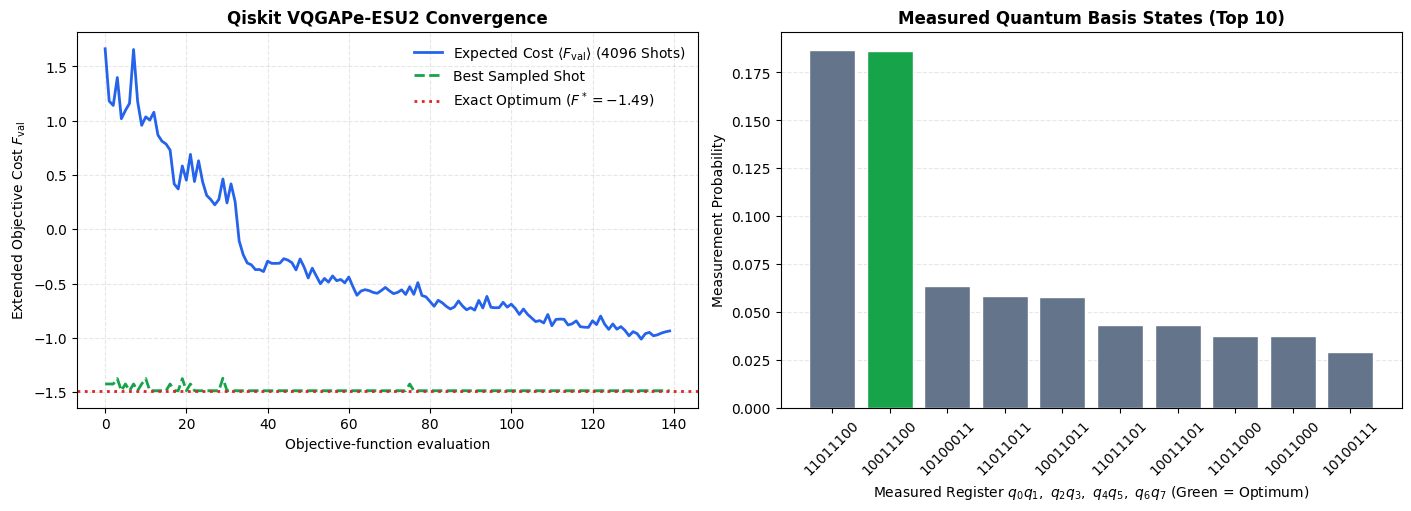

In [ ]:
# Use two panels: optimization progress on the left and the final basis-state
# probability distribution on the right.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')

# The expected cost is COBYLA's objective. The best sampled cost shows the
# best state encountered in each finite-shot objective evaluation.
ax1.plot(history_expected_cost, label=r'Expected Cost $\langle F_{\mathrm{val}} \rangle$ (4096 Shots)', color='#2563eb', lw=2)
ax1.plot(history_best_cost, label='Best Sampled Shot', color='#16a34a', linestyle='--', lw=2)
ax1.axhline(optimal_cost, color='#dc2626', linestyle=':', lw=2, label=f'Exact Optimum ($F^* = {optimal_cost:.2f}$)')
ax1.set_title('Qiskit VQGAPe-ESU2 Convergence', fontsize=12, fontweight='bold')
ax1.set_xlabel('Objective-function evaluation')
ax1.set_ylabel(r'Extended Objective Cost $F_{\mathrm{val}}$')
ax1.legend(frameon=False)
ax1.grid(alpha=0.3, linestyle='--')

# Sort states by final probability and display only the ten largest. Reverse
# each binary label to show qubits in q_0-to-q_7 register order.
top_k = 10
top_indices = np.argsort(final_probs)[::-1][:top_k]
top_labels = [format(idx, f'0{Q_vqgap_e}b')[::-1] for idx in top_indices]
top_probs = final_probs[top_indices]
colors = ['#16a34a' if idx == optimal_state_idx else '#64748b' for idx in top_indices]

ax2.bar(top_labels, top_probs, color=colors, edgecolor='white')
ax2.set_title('Measured Quantum Basis States (Top 10)', fontsize=12, fontweight='bold')
ax2.set_xlabel(r'Measured Register $q_0q_1,\ q_2q_3,\ q_4q_5,\ q_6q_7$ (Green = Optimum)')
ax2.set_ylabel('Measurement Probability')
ax2.tick_params(axis='x', rotation=45)
ax2.grid(axis='y', alpha=0.3, linestyle='--')
ax2.set_axisbelow(True)

plt.show()


## 7. Solution retrieval and capacity audit

Following **Section 1.6** of the report, the returned schedule is the lowest-cost feasible bitstring observed in the final $K$ measurements. The code below decodes that state using the VQGAPe mapping from **Section 1.7**, reconstructs $x_{nm}$, and verifies each residual budget

$$s_m=\max\left(0,b_m-\sum_{n=1}^{N}a_{nm}x_{nm}\right).$$

 STEP-BY-STEP DECODING FOR LOWEST-COST FEASIBLE FINAL SAMPLE |q0...q7⟩ = |10011100⟩
Rule from report Section 1.7: each task uses bits (e_{n,1}, e_{n,2}).
      Agent index: m = 1 + 2^0 * e_{n,1} + 2^1 * e_{n,2}  -->  x_nm = 1

• T1: RAG Vector Search Pipeline  
    Qubits (q_0, q_1) = |10⟩  -->  m = 1 + 1*(1) + 2*(0) = Agent 2
    One-Hot Row x_1 = [0, 1, 0, 0]  -->  Agent 2: AI/ML (9.5k)
    Metrics: Consumes 5,000 tokens | Expected Success Rate: 96%

• T2: Real-Time Fraud Telemetry   
    Qubits (q_2, q_3) = |01⟩  -->  m = 1 + 1*(0) + 2*(1) = Agent 3
    One-Hot Row x_2 = [0, 0, 1, 0]  -->  Agent 3: Security/Infra (9k)
    Metrics: Consumes 4,800 tokens | Expected Success Rate: 94%

• T3: Automated Code-Review Bot   
    Qubits (q_4, q_5) = |11⟩  -->  m = 1 + 1*(1) + 2*(1) = Agent 4
    One-Hot Row x_3 = [0, 0, 0, 1]  -->  Agent 4: Full-Stack (8.5k)
    Metrics: Consumes 4,600 tokens | Expected Success Rate: 91%

• T4: Distributed API Cache Layer 
    Qubits (q_6, q_7) = |00⟩  -->  m

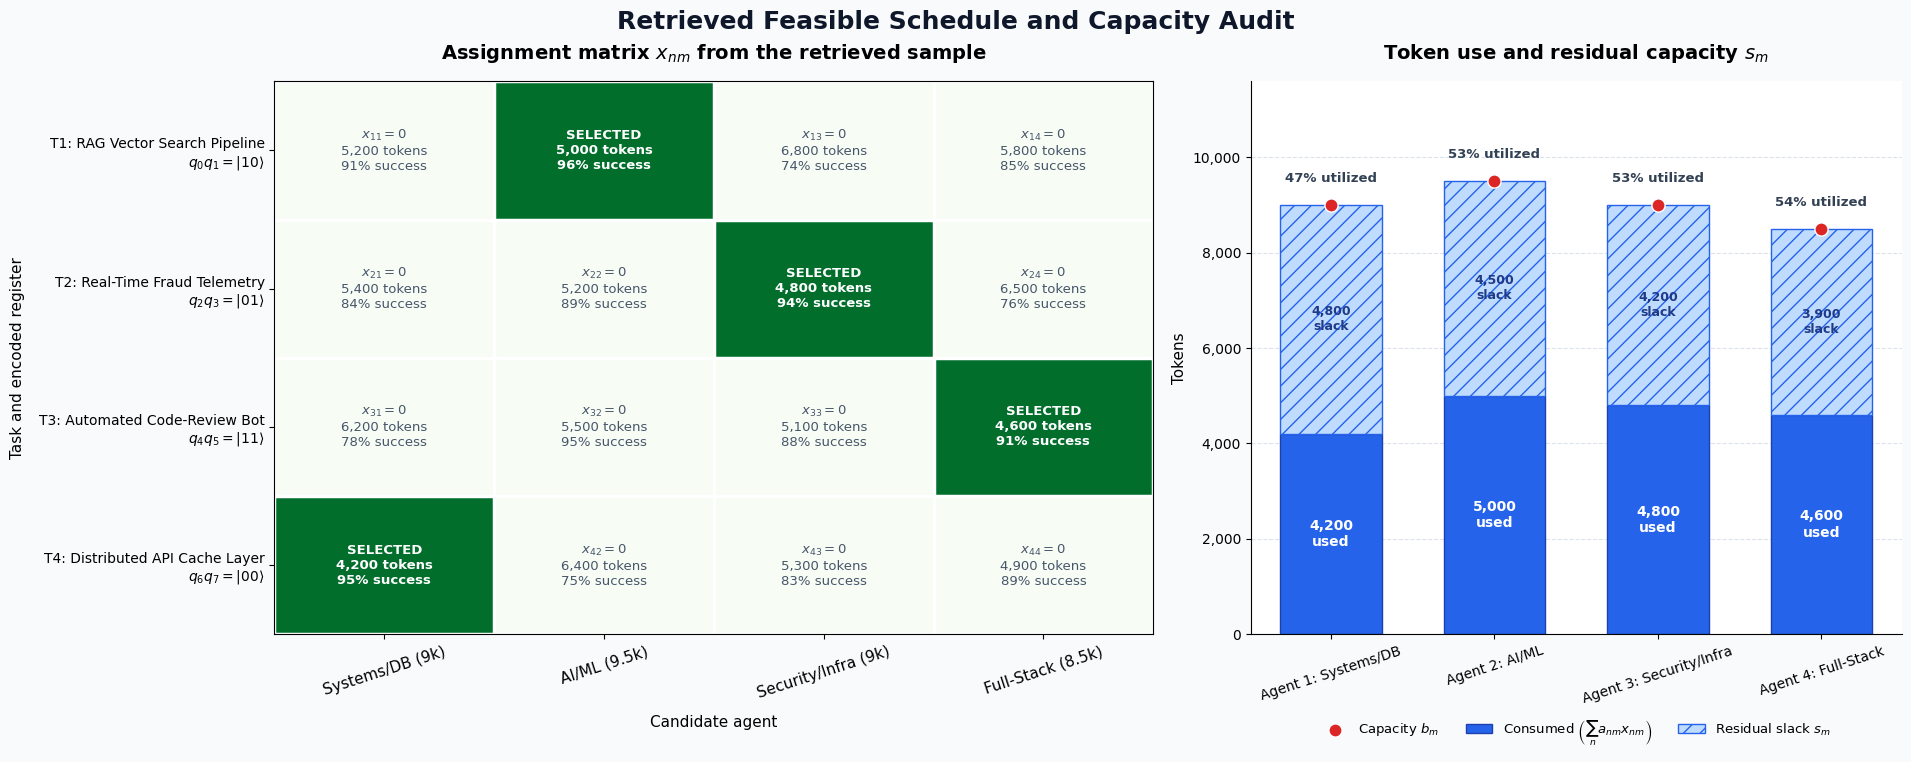

In [ ]:
# Qiskit's integer formatting prints the highest-index qubit first. Reverse
# the string so the displayed order is q_0, q_1, ..., q_7.
bitstring_q0_to_q7 = format(observed_best_state, f'0{Q_vqgap_e}b')[::-1]
decoded_x = decode_bitstring_to_x(observed_best_state)

print('=' * 80)
print(f' STEP-BY-STEP DECODING FOR LOWEST-COST FEASIBLE FINAL SAMPLE |q0...q7⟩ = |{bitstring_q0_to_q7}⟩')
print('=' * 80)
print('Rule from report Section 1.7: each task uses bits (e_{n,1}, e_{n,2}).')
print('      Agent index: m = 1 + 2^0 * e_{n,1} + 2^1 * e_{n,2}  -->  x_nm = 1\n')

# Decode and explain each two-qubit task register independently.
for n in range(N):
    q_idx_0, q_idx_1 = 2 * n, 2 * n + 1

    # Read e_{n,1} (weight 2^0) and e_{n,2} (weight 2^1).
    e_n1 = (observed_best_state >> q_idx_0) & 1
    e_n2 = (observed_best_state >> q_idx_1) & 1
    m_idx = e_n1 + 2 * e_n2

    # Convert the compact binary index back to the conventional one-hot row.
    one_hot_str = '[' + ', '.join(
        '1' if j == m_idx else '0' for j in range(M)
    ) + ']'

    print(f'• {tasks[n]:<32}')
    print(f'    Qubits (q_{q_idx_0}, q_{q_idx_1}) = |{e_n1}{e_n2}⟩  -->  m = 1 + 1*({e_n1}) + 2*({e_n2}) = Agent {m_idx + 1}')
    print(f'    One-Hot Row x_{n + 1} = {one_hot_str}  -->  {agents[m_idx]}')
    print(f'    Metrics: Consumes {a_raw[n, m_idx]:,} tokens | Expected Success Rate: {c_nm[n, m_idx] * 100:.0f}%\n')

# Recompute capacities in raw tokens for a human-readable final audit.
used_tokens_raw = np.sum(a_raw * decoded_x, axis=0)
residual_tokens_raw = np.maximum(0, b_raw - used_tokens_raw)

print('=' * 80)
print(' CLASSICAL RESIDUAL TOKEN BUDGET VERIFICATION: s_m = max(0, b_m - sum(a_nm * x_nm))')
print('=' * 80)
for m in range(M):
    status = 'FEASIBLE (Penalty = 0)' if used_tokens_raw[m] <= b_raw[m] else 'OVERFLOW!'
    print(f'• {agents[m]:<26} | Used: {int(used_tokens_raw[m]):>5,} / {b_raw[m]:>5,} tokens | Residual s_{m + 1} = {int(residual_tokens_raw[m]):>5,} tokens | {status}')

# Create a larger dashboard so long task and agent labels remain readable.
fig, (ax_mat, ax_bar) = plt.subplots(
    1,
    2,
    figsize=(19, 7.5),
    gridspec_kw={'width_ratios': [1.35, 1.0]},
    layout='constrained',
)
fig.patch.set_facecolor('#f8fafc')
fig.suptitle(
    'Retrieved Feasible Schedule and Capacity Audit',
    fontsize=18,
    fontweight='bold',
    color='#0f172a',
)

# --------------------------------------------------------------------------
# Panel A: one-hot assignment matrix
# --------------------------------------------------------------------------
ax_mat.set_facecolor('white')
ax_mat.imshow(decoded_x, cmap='Greens', vmin=0, vmax=1.15, aspect='auto')

agent_labels = [agent.split(':', 1)[1].strip() for agent in agents]
task_labels = [
    f'{tasks[n]}\n'
    f'$q_{{{2 * n}}}q_{{{2 * n + 1}}}='
    rf'|{bitstring_q0_to_q7[2 * n:2 * n + 2]}\rangle$'
    for n in range(N)
]

ax_mat.set_xticks(range(M), labels=agent_labels)
ax_mat.set_yticks(range(N), labels=task_labels)
ax_mat.tick_params(axis='x', rotation=18, labelsize=11)
ax_mat.tick_params(axis='y', labelsize=10)
ax_mat.set_title(
    r'Assignment matrix $x_{nm}$ from the retrieved sample',
    fontsize=14,
    fontweight='bold',
    pad=16,
)
ax_mat.set_xlabel('Candidate agent', fontsize=11, labelpad=10)
ax_mat.set_ylabel('Task and encoded register', fontsize=11, labelpad=10)

# Draw cell boundaries to make the matrix read like a schedule table.
ax_mat.set_xticks(np.arange(-0.5, M, 1), minor=True)
ax_mat.set_yticks(np.arange(-0.5, N, 1), minor=True)
ax_mat.grid(which='minor', color='white', linewidth=2.5)
ax_mat.tick_params(which='minor', bottom=False, left=False)

# Annotate every candidate assignment. The selected cells use white text
# against the dark-green heatmap value and include an explicit check mark.
for n in range(N):
    for m in range(M):
        is_assigned = bool(decoded_x[n, m])
        assignment_text = 'SELECTED' if is_assigned else r'$x_{{{}{}}}=0$'.format(n + 1, m + 1)
        metric_text = (
            f'{a_raw[n, m]:,} tokens\n'
            f'{c_nm[n, m] * 100:.0f}% success'
        )
        ax_mat.text(
            m,
            n,
            f'{assignment_text}\n{metric_text}',
            ha='center',
            va='center',
            color='white' if is_assigned else '#475569',
            fontsize=9.5,
            fontweight='bold' if is_assigned else 'normal',
        )

# --------------------------------------------------------------------------
# Panel B: consumed capacity plus residual slack
# --------------------------------------------------------------------------
x_pos = np.arange(M)
agent_short_names = [agent.split('(')[0].strip() for agent in agents]
bar_width = 0.62

used_bars = ax_bar.bar(
    x_pos,
    used_tokens_raw,
    width=bar_width,
    label=r'Consumed $\left(\sum_n a_{nm}x_{nm}\right)$',
    color='#2563eb',
    edgecolor='#1e40af',
    linewidth=1.0,
)
slack_bars = ax_bar.bar(
    x_pos,
    residual_tokens_raw,
    width=bar_width,
    bottom=used_tokens_raw,
    label=r'Residual slack $s_m$',
    color='#bfdbfe',
    edgecolor='#2563eb',
    linewidth=1.0,
    hatch='//',
)
ax_bar.scatter(
    x_pos,
    b_raw,
    color='#dc2626',
    edgecolor='white',
    linewidth=1.0,
    zorder=5,
    s=90,
    label=r'Capacity $b_m$',
)

# Label consumed and residual portions and report utilization above each bar.
for m, (used_bar, slack_bar) in enumerate(zip(used_bars, slack_bars)):
    used = used_tokens_raw[m]
    slack = residual_tokens_raw[m]
    utilization = 100 * used / b_raw[m]

    if used > 0:
        ax_bar.text(
            used_bar.get_x() + used_bar.get_width() / 2,
            used / 2,
            f'{used:,.0f}\nused',
            ha='center',
            va='center',
            color='white',
            fontsize=10,
            fontweight='bold',
        )
    if slack > 0:
        ax_bar.text(
            slack_bar.get_x() + slack_bar.get_width() / 2,
            used + slack / 2,
            f'{slack:,.0f}\nslack',
            ha='center',
            va='center',
            color='#1e3a8a',
            fontsize=9,
            fontweight='bold',
        )

    ax_bar.text(
        m,
        b_raw[m] + 420,
        f'{utilization:.0f}% utilized',
        ha='center',
        va='bottom',
        color='#334155',
        fontsize=9.5,
        fontweight='bold',
    )

ax_bar.set_xticks(x_pos, labels=agent_short_names)
ax_bar.tick_params(axis='x', rotation=18, labelsize=10)
ax_bar.set_ylabel('Tokens', fontsize=11)
ax_bar.set_ylim(0, max(b_raw) * 1.22)
ax_bar.yaxis.set_major_formatter('{x:,.0f}')
ax_bar.set_title(
    r'Token use and residual capacity $s_m$',
    fontsize=14,
    fontweight='bold',
    pad=16,
)
ax_bar.grid(axis='y', color='#cbd5e1', alpha=0.65, linestyle='--')
ax_bar.set_axisbelow(True)
for spine_name in ('top', 'right'):
    ax_bar.spines[spine_name].set_visible(False)
ax_bar.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, -0.13),
    ncol=3,
    frameon=False,
    fontsize=9.5,
)

plt.show()


## Reproducibility note

The reported assignment is the lowest-cost feasible state found in the final $K=4096$ simulated measurements. Exact enumeration is included only as a small-instance verification benchmark; it is not part of the scalable VQGAPe workflow described in the report. The task costs, success rates, and capacities in this notebook define the submitted demonstration instance.